# Stateful actor: a parameter server

An actor keeps state between calls. One node creates the ParameterServer actor and a second node calls its set method.

**When to use it.** When workers must share mutable state, for example model weights, a cache or a counter, that would be lost between independent tasks.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

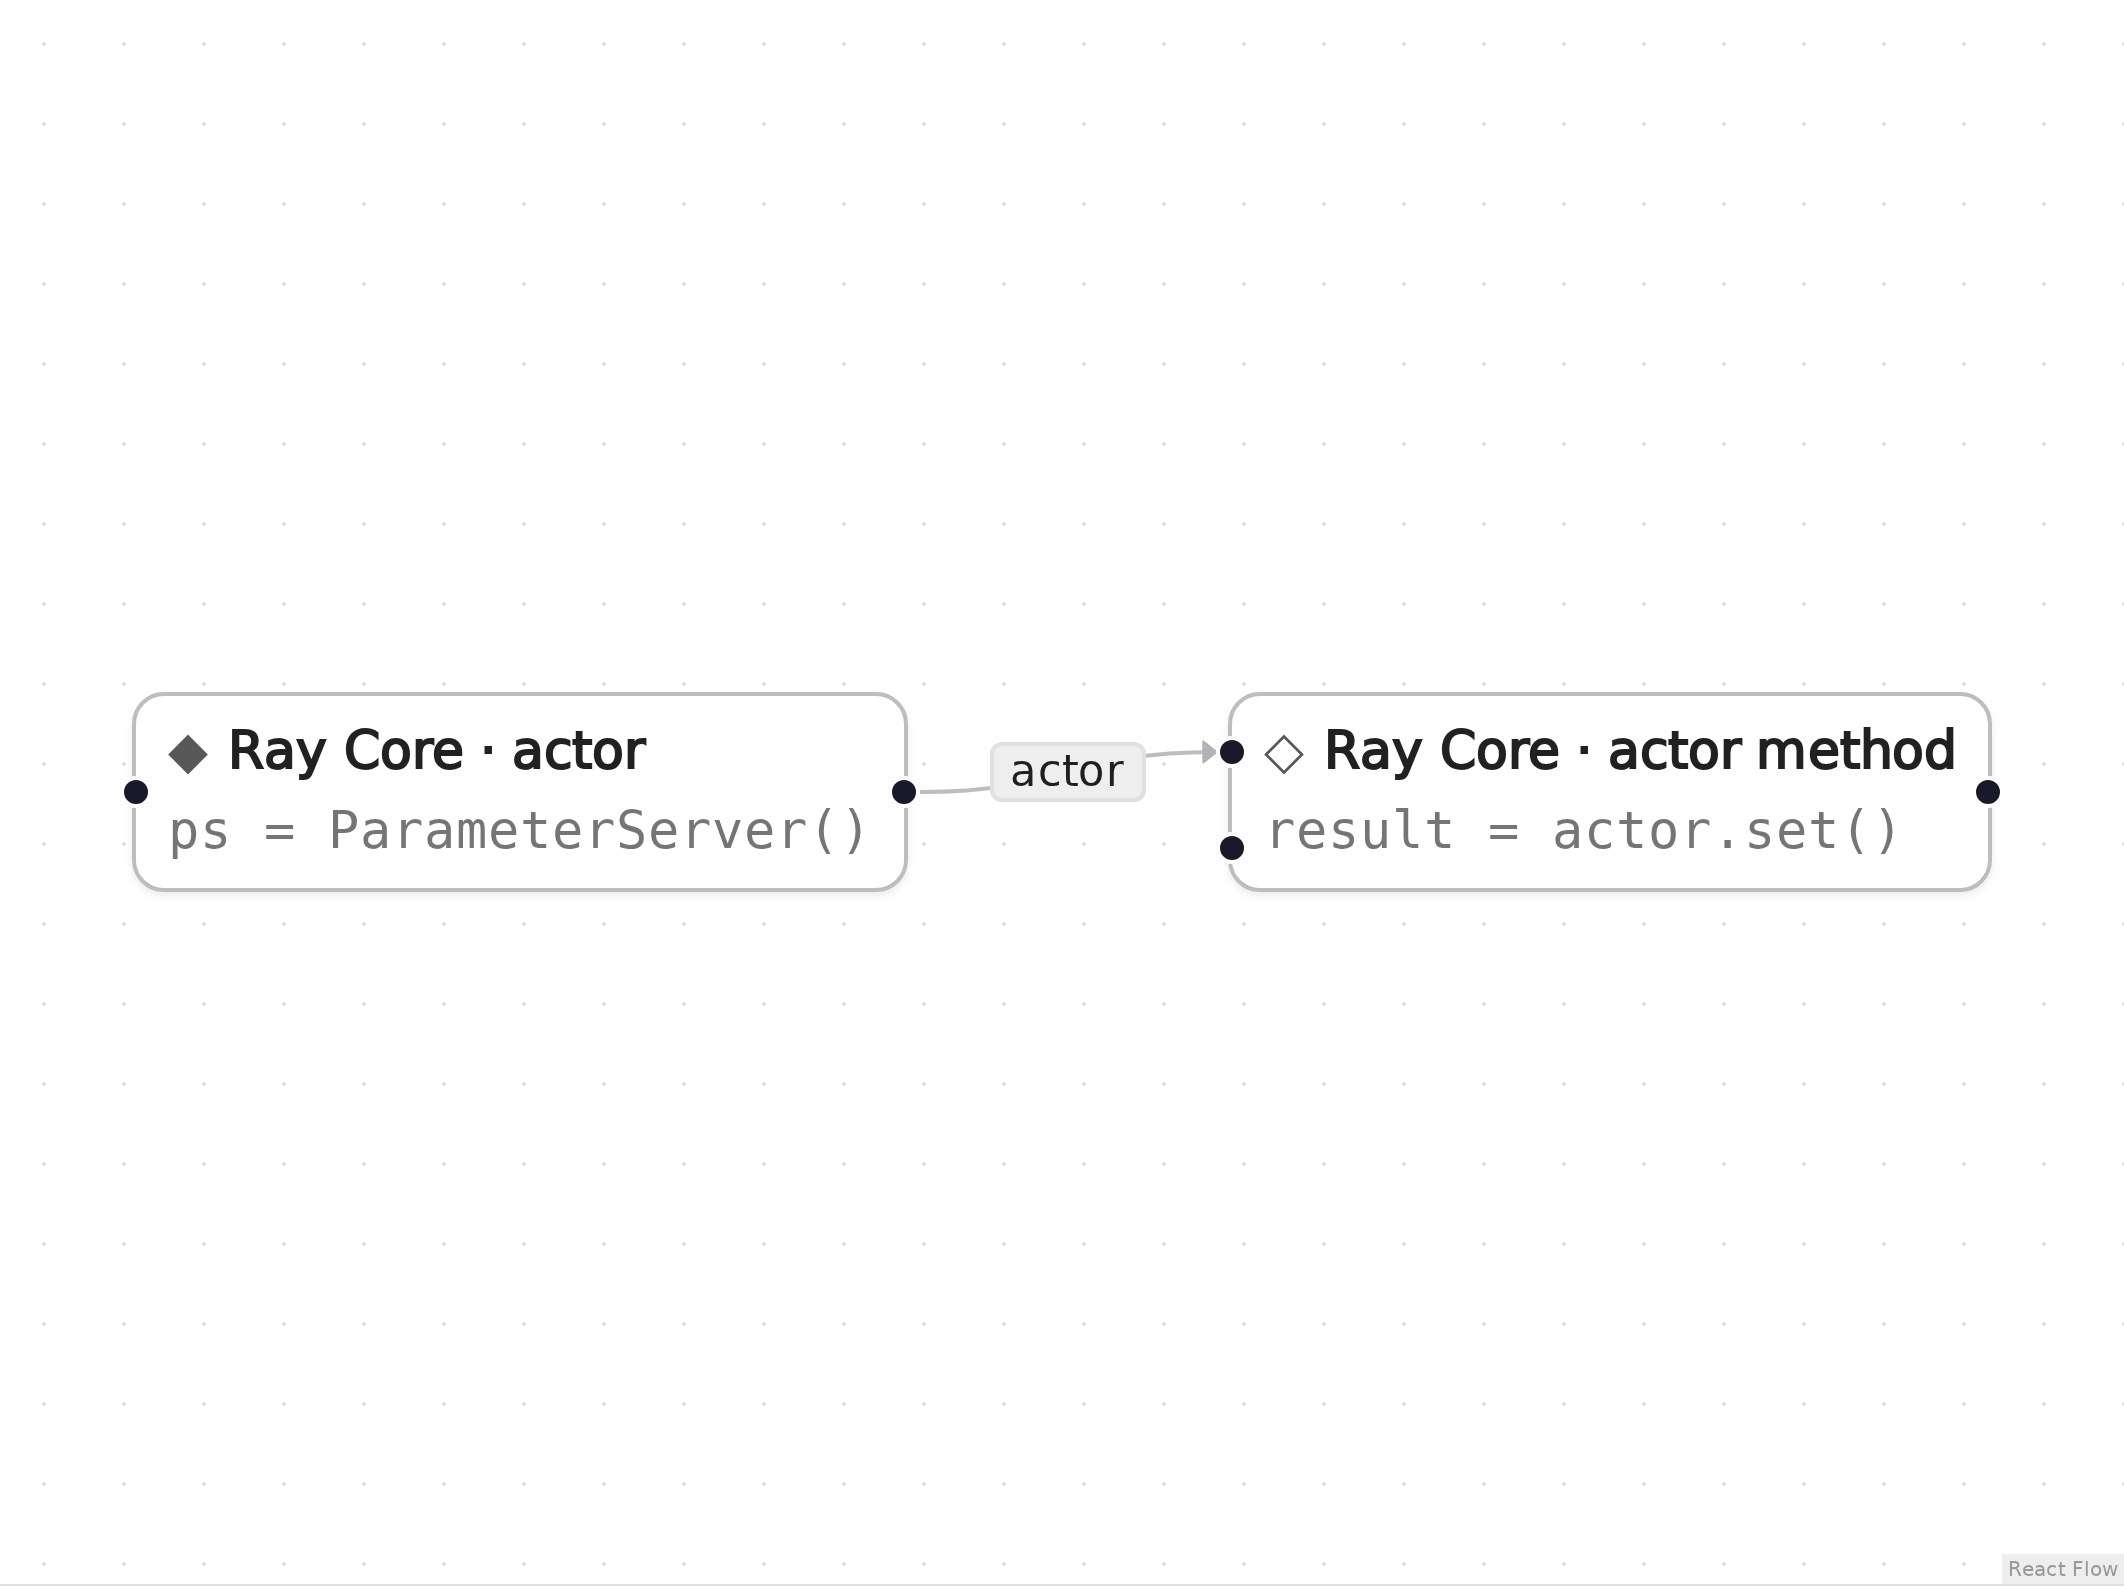

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
class ParameterServer:
    # Leave the class undecorated: the generated code wraps it with ray.remote for you.
    def __init__(self):
        self.state = {}

    def set(self, key, value):
        self.state[key] = value
        return value

    def get(self, key):
        return self.state.get(key)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ps = ray.remote(ParameterServer).remote()
_n2 = ps.set.remote("w", 42)
result = ray.get(_n2)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert result == 42, result
assert ray.get(ps.get.remote("w")) == 42
print("ps.get('w') =", ray.get(ps.get.remote("w")))

ps.get('w') = 42


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Actor** (node `n1`, line 8)

```python
ps = ray.remote(ParameterServer).remote()
```

Creates one actor process from the ParameterServer class. The handle ps is what other nodes use to call methods.

**Actor method** (node `n2`, lines 9–10)

```python
_n2 = ps.set.remote("w", 42)
result = ray.get(_n2)
```

The method node is wired to the actor handle. ps.set.remote("w", 42) runs inside the actor, and ray.get returns the stored value.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()